# Anatomía de una serie: descomponer antes de predecir

**Avanzado · Jornada 1 · Bloque 1.3 · diapositivas tres-ritmos, stl, acf, minimo-nocturno, media-esconde, ejercicio-nocturno, cusum-idea, ejercicio-nocturno-2 y solucion-nocturno**

¿Qué ritmos tiene el uso de BiciCiudad y dónde se esconde una avería pequeña? Tres estacionalidades,
autocorrelación, STL, el consumo cada 15 minutos y el mínimo nocturno de una base. Y el ejercicio:
¿cuál de las cuatro bases pierde energía, y desde cuándo?

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## La pregunta

Cuatro bases de carga, B-05, B-14, B-26 y B-38, y dos años de consumo cada cuarto de hora. Una
pierde energía; las otras tres, no. ¿Cuál, y desde cuándo?

Para contestarlo hay que entender antes la forma de las series: sus ritmos, cuánto se parecen a
sí mismas y qué queda cuando se quita lo que se repite.

> **Mensaje clave del bloque:** una media mensual esconde exactamente lo que se busca.

In [2]:
# Ayudas de formato en español: números, porcentajes, fechas y ejes.


def n(x, decimales=0):
    """Número en español: 1.234,5, con el signo menos tipográfico (−)."""
    return estilo.num(x, decimales).replace("-", "−")


def pct(x, decimales=1):
    """Proporción como porcentaje: 0,133 → «13,3 %»."""
    return n(100 * x, decimales) + " %"


def fecha(t):
    """Fecha como en las diapositivas: 18-5-2026."""
    t = pd.Timestamp(t)
    return f"{t.day}-{t.month}-{t.year}"


import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]


def eje_es(ax, eje="y", decimales=0, sufijo=""):
    """Etiquetas de un eje con números en español."""
    formato = FuncFormatter(lambda v, _: n(v, decimales) + sufijo)
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(formato)


def eje_meses(ax, meses=(1, 4, 7, 10)):
    """Eje de fechas con el mes en español: «ene 2026»."""
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=meses))
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f"{MESES[mdates.num2date(v).month - 1]} {mdates.num2date(v).year}"))

## 1. El uso late a tres ritmos

Viajes por hora del sistema durante tres años, con el calendario de festivos (diapositiva `tres-ritmos`).

In [3]:
viajes = pd.read_csv(DATOS / "uso_meteo" / "viajes_sistema_hora.csv")
calendario = pd.read_csv(DATOS / "uso_meteo" / "calendario.csv")
viajes = viajes.merge(calendario, left_on="fecha_local", right_on="fecha")

# El día: viajes medios por hora, laborable frente a fin de semana y festivo.
perfil = viajes.groupby(["hora_local", "laborable"])["viajes"].mean().unstack()
print("Laborable: pico de mañana a las", perfil[True].loc[:12].idxmax(), "h con", n(perfil[True].loc[:12].max()),
      "viajes; de tarde a las", perfil[True].loc[12:].idxmax(), "h con", n(perfil[True].loc[12:].max()))
print("Fin de semana y festivo: pico a las", perfil[False].idxmax(), "h con", n(perfil[False].max()))

# La semana: viajes medios al día por día de la semana.
por_dia = viajes.groupby("fecha_local").agg(viajes=("viajes", "sum"), dia=("dia_semana", "first"))
orden = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
print(por_dia.groupby("dia")["viajes"].mean().reindex(orden).map(n).to_string())

Laborable: pico de mañana a las 8 h con 1.533 viajes; de tarde a las 18 h con 1.573
Fin de semana y festivo: pico a las 12 h con 937
dia
lunes        14.035
martes       14.012
miércoles    13.895
jueves       13.870
viernes      13.982
sábado       11.001
domingo       9.556


Doble joroba en laborable (entrada y salida del trabajo), una sola y suave en festivo, y el fin de
semana muy por debajo. Cualquier comparación ingenua (un martes con el domingo anterior, julio con
agosto) mezcla los tres ritmos.

## 2. La serie se parece a sí misma: ACF y PACF

La **autocorrelación** (ACF) es la correlación de la serie consigo misma desplazada unas horas.
Ocho semanas de viajes horarios de otoño de 2025 (diapositiva `acf`).

In [4]:
from statsmodels.tsa.stattools import acf, pacf

inicio, fin = "2025-10-06", "2025-11-30"   # ← ocho semanas
fechas = pd.to_datetime(viajes["fecha_local"])
serie_horaria = viajes.loc[(fechas >= inicio) & (fechas <= fin), "viajes"].to_numpy()

r = acf(serie_horaria, nlags=336)
print("Horas:", n(len(serie_horaria)))
for desfase in [12, 24, 168, 336]:
    print(f"  desfase {desfase:>3} h: {n(r[desfase], 2)}")

Horas: 1.345
  desfase  12 h: −0,05
  desfase  24 h: 0,79
  desfase 168 h: 0,81
  desfase 336 h: 0,66


A las 24 horas, 0,79; a la semana, 0,81, la más alta: lo que pasa este martes a las ocho se parece
más al martes pasado a las ocho que a ayer, que pudo ser domingo. A las 12 horas, nada.

La **autocorrelación parcial** (PACF) quita lo que ya explican las horas intermedias: ¿cuánto
aporta saber lo de hace 24 horas **si ya sé** lo de la hora anterior?

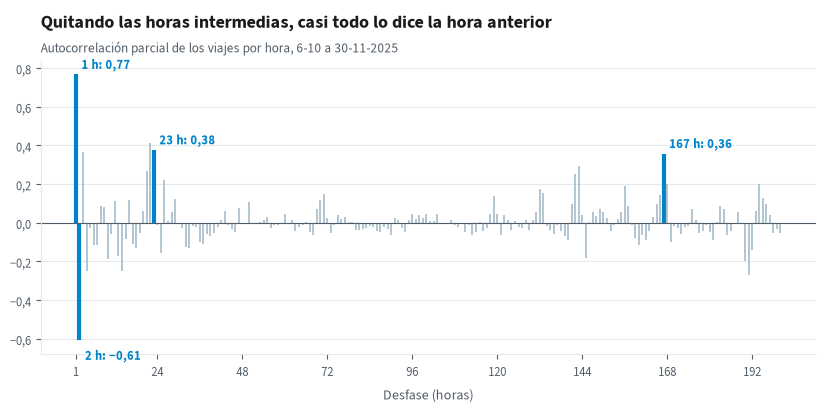

In [5]:
rp = pacf(serie_horaria, nlags=200)
desfases = np.arange(1, 201)
destacar = (desfases <= 2) | np.isin(desfases, [23, 167])

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.vlines(desfases, 0, rp[1:], color=np.where(destacar, estilo.AZUL, estilo.GRIS),
          linewidth=np.where(destacar, 3, 1.2))
ax.axhline(0, color=estilo.TEXTO_2, linewidth=0.8)
for k in [1, 2, 23, 167]:
    ax.annotate(f"{k} h: {n(rp[k], 2)}", (k, rp[k]), xytext=(4, 4 if rp[k] > 0 else -14),
                textcoords="offset points", color=estilo.AZUL, fontsize=9, weight="bold")
ax.set_xticks([1, 24, 48, 72, 96, 120, 144, 168, 192])
eje_es(ax, decimales=1)
ax.set_xlabel("Desfase (horas)")
ax.set_title("Quitando las horas intermedias, casi todo lo dice la hora anterior")
estilo.subtitulo(ax, "Autocorrelación parcial de los viajes por hora, 6-10 a 30-11-2025")
plt.show()

La serie es casi toda «inercia»: la hora anterior y la de antes explican la mayor parte. Quedan
picos más pequeños cerca de un día y de una semana. Dos consecuencias: mañana, el rival más duro
de un modelo de previsión será «lo mismo que la semana pasada»; y dentro de un rato, en el bloque
de inferencia, veremos que estos datos **no son independientes**.

## 3. STL: lo que se repite y lo que sorprende

Consumo diario de la base B-07 durante dos años, partido en tendencia, estacionalidad semanal y
residuo (diapositiva `stl`). **Cambiad el periodo** y mirad qué pasa: con 7 días la tendencia se
queda con el ritmo anual; con 365, la estacionalidad intenta llevárselo.

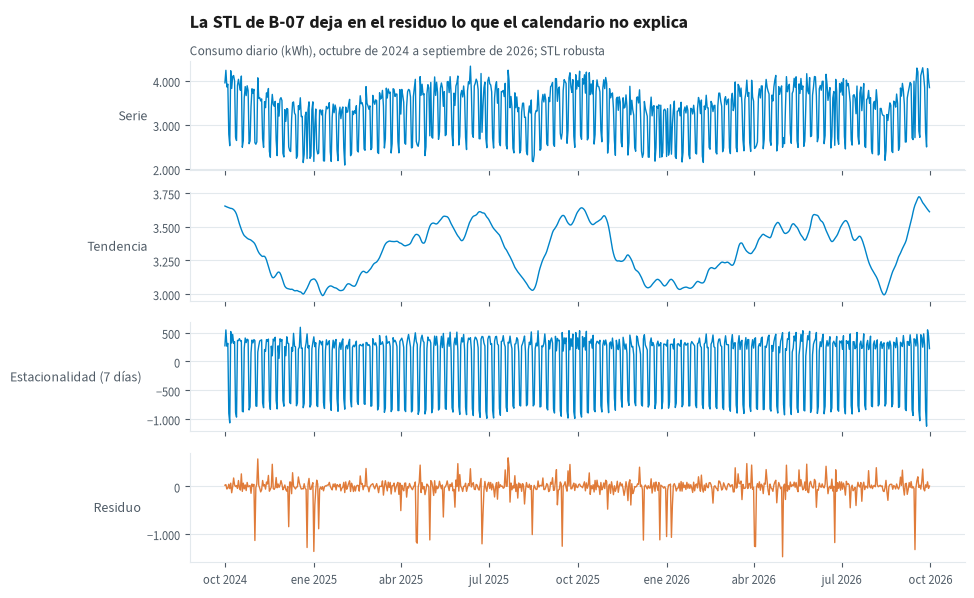

Estacionalidad de −1.125 a 594 kWh; residuo de −1.483 a 602 kWh


In [6]:
from statsmodels.tsa.seasonal import STL

base_stl = "B-07"   # ← cualquier base, de B-01 a B-40
periodo = 7         # ← probad 30 o 365

diario = pd.read_csv(DATOS / "energia_bases" / "diario.csv", parse_dates=["fecha"])
consumo = diario[diario["base_id"] == base_stl].set_index("fecha")["consumo_kwh"].asfreq("D")
stl = STL(consumo, period=periodo, robust=True).fit()   # robusta: unos pocos días raros no deforman la tendencia

fig, ejes = plt.subplots(4, 1, figsize=(10, 6.5), sharex=True)
partes = [("Serie", consumo), ("Tendencia", stl.trend),
          (f"Estacionalidad ({periodo} días)", stl.seasonal), ("Residuo", stl.resid)]
for ax, (nombre, valores) in zip(ejes, partes):
    ax.plot(valores.index, valores.values, linewidth=1,
            color=estilo.NARANJA if nombre == "Residuo" else estilo.AZUL)
    ax.set_ylabel(nombre, rotation=0, ha="right", va="center")
    eje_es(ax)
eje_meses(ejes[-1])
ejes[0].set_title(f"La STL de {base_stl} deja en el residuo lo que el calendario no explica")
estilo.subtitulo(ejes[0], "Consumo diario (kWh), octubre de 2024 a septiembre de 2026; STL robusta")
plt.show()
print(f"Estacionalidad de {n(stl.seasonal.min())} a {n(stl.seasonal.max())} kWh; "
      f"residuo de {n(stl.resid.min())} a {n(stl.resid.max())} kWh")

En fórmula (la franja de `stl`): **y(t) = T(t) + S(t) + R(t)**. Cada día es su nivel de fondo,
más lo que toca por ser ese día de la semana, más lo que sobra. Un día concreto:

In [7]:
dia_stl = pd.Timestamp("2026-05-01")   # ← un viernes festivo: la Fiesta del Trabajo
print(f"{fecha(dia_stl)}: {n(consumo[dia_stl])} = {n(stl.trend[dia_stl])} + {n(stl.seasonal[dia_stl])} "
      f"+ ({n(stl.resid[dia_stl])}) kWh")

1-5-2026: 2.490 = 3.473 + 500 + (−1.483) kWh


La semana esperaba un viernes alto (+500 kWh), pero era festivo: el residuo de −1.483 kWh es el
más bajo de los dos años. Ojo con la tendencia: con un periodo de 7 días se queda también con el
ritmo anual (se hunde en agosto), así que no es «lo que crece».

Los picos hacia abajo del residuo son, sobre todo, festivos: días que el calendario semanal no
conoce. Ahí vivirán las anomalías de la Jornada 2: detectar sobre el residuo es mucho más fácil
que pelearse con la estacionalidad.

## 4. La granularidad importa: cada 15 minutos

El consumo de una base llega cada cuarto de hora. Tres días laborables de B-07 (diapositiva
`minimo-nocturno`): ¿cuánto gasta entre las 3:00 y las 4:00, cuando casi no se carga ninguna bici?

In [8]:
quince = pd.read_parquet(DATOS / "energia_bases" / "quince_min_ejercicio.parquet")
quince["base_id"] = quince["base_id"].astype(str)
quince["local"] = bici.hora_local(quince["ts_utc"])
quince["fecha"] = quince["local"].dt.strftime("%Y-%m-%d")
print("Filas:", n(len(quince)), "· Bases:", sorted(quince["base_id"].unique()))

b07 = quince[(quince["base_id"] == "B-07") & quince["fecha"].between("2026-02-02", "2026-02-04")]
de_3_a_4 = b07[b07["local"].dt.hour == 3]
print("Pico de los tres días:", n(b07["kw"].max(), 1), "kW")
print("Mínimo de 3:00 a 4:00, cada noche:", [n(v, 1) for v in de_3_a_4.groupby("fecha")["kw"].min()], "kW")
print("Media de 3:00 a 4:00, cada noche: ", [n(v, 1) for v in de_3_a_4.groupby("fecha")["kw"].mean()], "kW")

Filas: 350.400 · Bases: ['B-05', 'B-07', 'B-14', 'B-26', 'B-38']
Pico de los tres días: 374,4 kW
Mínimo de 3:00 a 4:00, cada noche: ['21,9', '22,3', '22,1'] kW
Media de 3:00 a 4:00, cada noche:  ['23,0', '23,1', '22,9'] kW


Unos 22 kW cada noche, casi idénticos: eso es lo valioso. El mínimo nocturno de una base sana
apenas se mueve de una noche a otra. Si sube y no baja, algo consume energía que no llega a ninguna
bici. Con datos horarios veríamos la media de la hora, algo más alta y más ruidosa; con los cuartos
de hora, el mínimo de verdad.

En `energia_bases/diario.csv` ese mínimo ya viene calculado (`minimo_nocturno_kw`): el menor de
los cuatro cuartos de hora entre las 3:00 y las 4:00, hora local. Lo comprobamos:

In [9]:
minimo_15 = quince[quince["local"].dt.hour == 3].groupby(["fecha", "base_id"])["kw"].min().unstack()
minimo_diario = diario.assign(fecha=diario["fecha"].dt.strftime("%Y-%m-%d")).pivot(
    index="fecha", columns="base_id", values="minimo_nocturno_kw")[minimo_15.columns]
print("Mayor diferencia entre los dos cálculos:", n((minimo_15 - minimo_diario).abs().max().max(), 4), "kW")

Mayor diferencia entre los dos cálculos: 0,0000 kW


## 5. La media mensual no ve la avería

La base B-12 tiene una avería gradual desde el 1 de diciembre de 2025 (diapositiva `media-esconde`).
Comparad la media mensual del consumo con la del mínimo nocturno.

In [10]:
b12 = diario[diario["base_id"] == "B-12"].set_index("fecha")["2025-10-01":"2026-09-30"]
mensual = pd.DataFrame({"consumo medio (kWh/día)": b12["consumo_kwh"].resample("MS").mean(),
                        "mínimo nocturno medio (kW)": b12["minimo_nocturno_kw"].resample("MS").mean()})
mensual.index = mensual.index.strftime("%Y-%m")
print(f"Consumo medio: de {n(mensual.iloc[:, 0].min())} a {n(mensual.iloc[:, 0].max())} kWh al día según el mes")
print(f"Mínimo nocturno: de {n(mensual.iloc[0, 1], 1)} a {n(mensual.iloc[-1, 1], 1)} kW")
mensual.round(1)

Consumo medio: de 2.865 a 3.490 kWh al día según el mes
Mínimo nocturno: de 14,9 a 16,3 kW


,consumo medio (kWh/día),mínimo nocturno medio (kW)
fecha,,
2025-10,3441.8,14.9
2025-11,3074.3,14.7
2025-12,2925.1,14.9
2026-01,2864.5,14.9
2026-02,3045.6,15.2
2026-03,3163.5,15.4
2026-04,3258.8,15.5
2026-05,3311.3,15.7
2026-06,3409.3,15.8


In [11]:
# Peso de la avería = aumento ÷ nivel (la franja de media-esconde).
aumento = mensual.iloc[-1, 1] - mensual.iloc[0, 1]          # kW de más, de octubre a septiembre
consumo_anual = b12["consumo_kwh"].mean()                     # kWh al día, media del año
print(f"{n(aumento, 3)} kW × 24 h = {n(24 * aumento)} kWh al día")
print(f"Sobre el consumo: {n(24 * aumento)} ÷ {n(consumo_anual)} = {pct(24 * aumento / consumo_anual)}")
print(f"Sobre el mínimo:  {n(aumento, 3)} ÷ {n(mensual.iloc[0, 1], 1)} = {pct(aumento / mensual.iloc[0, 1])}")

1,346 kW × 24 h = 32 kWh al día
Sobre el consumo: 32 ÷ 3.190 = 1,0 %
Sobre el mínimo:  1,346 ÷ 14,9 = 9,0 %


Unos 1,3 kW más (1,35 sin redondear) durante 24 horas son unos 32 kWh al día: el 1 % de lo que
consume la base, enterrado
bajo una estación que mueve la media más de un 20 %. El mínimo nocturno no tiene estación que lo
tape: el 1 % de la media es casi el 10 % del mínimo.

## 6. Ejercicio, primera parte: ¿cuál de las cuatro bases pierde energía? (15 min)

**Paso 1. Descomponer.** Pasamos los cuartos de hora a consumo diario y hacemos la STL de cada base.
Os adelanto que a lo mejor no veis nada, y eso también es un resultado.

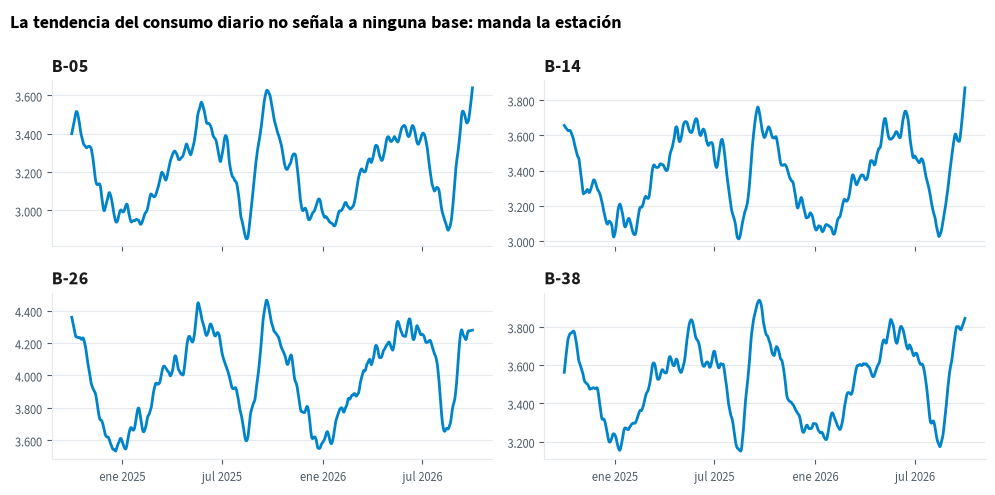

In [12]:
bases = ["B-05", "B-14", "B-26", "B-38"]
ejercicio_15 = quince[quince["base_id"].isin(bases)]

# kWh del día = suma de los kW de cada cuarto de hora × 0,25 h.
consumo_dia = (ejercicio_15.groupby(["fecha", "base_id"])["kw"].sum() * 0.25).unstack()
consumo_dia.index = pd.to_datetime(consumo_dia.index)

fig, ejes = plt.subplots(2, 2, figsize=(10, 5), sharex=True)
for ax, base in zip(ejes.flat, bases):
    tendencia = STL(consumo_dia[base].asfreq("D"), period=7, robust=True).fit().trend
    ax.plot(tendencia.index, tendencia.values, color=estilo.AZUL)
    ax.set_title(base, pad=6)
    eje_es(ax)
    eje_meses(ax, meses=(1, 7))
fig.suptitle("La tendencia del consumo diario no señala a ninguna base: manda la estación",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

**Paso 2. Mirar el mínimo nocturno.** Para cada noche, el menor de los cuatro cuartos de hora entre
las 3:00 y las 4:00, las cuatro bases en el mismo gráfico. Si el ruido os molesta, una media móvil
de unos días ayuda.

In [13]:
ventana = 1   # ← días de la media móvil: probad 7
titulo = "¿Qué base se separa de su propio nivel?"   # ← cuando lo sepáis, escribid la conclusión

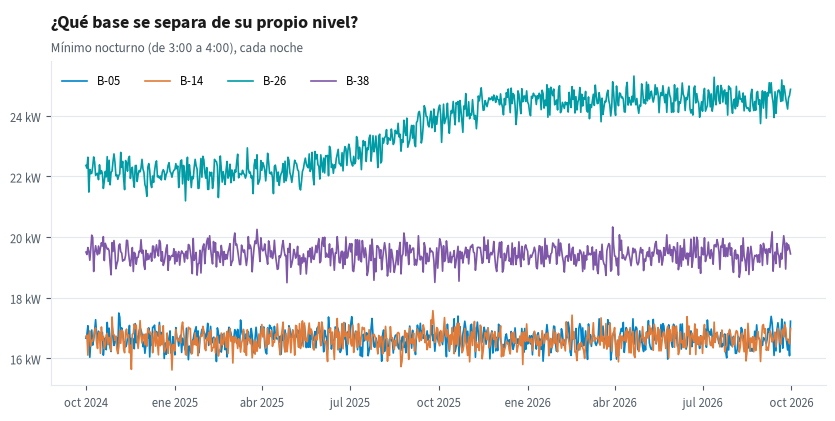

In [14]:
minimo = minimo_15[bases].copy()
minimo.index = pd.to_datetime(minimo.index)
suavizado = minimo.rolling(ventana, center=True).mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
for base, color in zip(bases, estilo.SERIES):
    ax.plot(suavizado.index, suavizado[base], color=color, linewidth=1.2, label=base)
eje_es(ax, sufijo=" kW")
eje_meses(ax)
ax.legend(ncol=4, loc="upper left")
ax.set_title(titulo)
suavizado_texto = "cada noche" if ventana == 1 else f"media móvil de {ventana} días"
estilo.subtitulo(ax, f"Mínimo nocturno (de 3:00 a 4:00), {suavizado_texto}")
plt.show()

## 7. La suma acumulada (CUSUM), con B-12

La herramienta de la segunda parte del ejercicio (diapositiva `cusum-idea`):

**S(t) = máx(0; S(t − 1) + (x(t) − μ) ÷ σ − k)**, y alarma si S(t) > h.

Cada noche se suma cuánto se pasa el mínimo de lo normal, en sigmas (σ = rango móvil medio ÷
1,128), menos una holgura k. Si la suma baja de cero, vuelve a cero. Antes de usarla en el
ejercicio, la probamos con B-12, la base de `media-esconde`, con una referencia anterior a su avería.

In [15]:
noche_b12 = diario[diario["base_id"] == "B-12"].set_index("fecha")["minimo_nocturno_kw"]
ref_b12 = noche_b12["2025-08-15":"2025-11-30"]                 # ← periodo sano de referencia
mu_b12 = ref_b12.mean()
sigma_b12 = ref_b12.diff().abs().mean() / 1.128                # rango móvil medio ÷ 1,128
print(f"B-12: μ = {n(mu_b12, 2)} kW, σ = {n(sigma_b12, 2)} kW")

suma_b12, sumas_b12 = 0.0, {}
for dia, valor in noche_b12["2025-12-01":"2025-12-18"].items():
    suma_b12 = max(0.0, suma_b12 + (valor - mu_b12) / sigma_b12 - 0.5)   # k = 0,5
    sumas_b12[dia] = suma_b12
sumas_b12 = pd.Series(sumas_b12)
for dia in pd.to_datetime(["2025-12-08", "2025-12-09", "2025-12-10", "2025-12-16", "2025-12-17", "2025-12-18"]):
    print(f"  {fecha(dia)}: mínimo {n(noche_b12[dia], 2)} kW → suma {n(sumas_b12[dia], 2)}")

B-12: μ = 14,82 kW, σ = 0,29 kW
  8-12-2025: mínimo 15,10 kW → suma 0,49
  9-12-2025: mínimo 14,90 kW → suma 0,27
  10-12-2025: mínimo 14,83 kW → suma 0,00
  16-12-2025: mínimo 15,22 kW → suma 0,91
  17-12-2025: mínimo 15,17 kW → suma 1,64
  18-12-2025: mínimo 15,20 kW → suma 2,47


El 8 de diciembre la suma sube un poco y el 10 ya ha vuelto a cero: el ruido se anula solo. Del 16
al 18, con unos 15,2 kW cada noche, la suma crece sin parar: la avería se acumula. Cuándo pasa de
h = 5 lo veremos en la Jornada 4.

## 8. Ejercicio, segunda parte: pon fecha al cambio y di con qué margen (13 min, tras la pausa)

1. Elegid un **periodo de referencia** en el que la base estaba sana. Ojo con elegirlo mirando el
   gráfico: si metéis parte de la avería en la referencia, la fecha saldrá tarde.
2. Calculad su **media** y cuánto varía de una noche a otra.
3. Buscad el día en que el mínimo se separa: a ojo, o con la **suma acumulada (CUSUM)** del
   apartado 7. Cambiad *k* y *h* y mirad cómo se mueve la alarma.

In [16]:
base_candidata = "B-05"   # ← la que hayáis elegido en la primera parte

In [17]:
referencia_inicio, referencia_fin = "2024-10-01", "2025-04-30"   # ← periodo sano de referencia
k = 0.5   # ← descuento por noche, en desviaciones típicas
h = 5     # ← umbral de alarma

serie = minimo[base_candidata]
referencia = serie[referencia_inicio:referencia_fin]
media = referencia.mean()
sigma = referencia.diff().abs().mean() / 1.128   # variación de una noche a otra (rango móvil)
print(f"{base_candidata}: referencia {n(media, 2)} kW, variación típica {n(sigma, 2)} kW")

# CUSUM: desde el día siguiente a la referencia.
vigilancia = serie[pd.Timestamp(referencia_fin) + pd.Timedelta(days=1):]
suma, cusum, alarma, ultimo_cero = 0.0, [], None, None
for dia, valor in vigilancia.items():
    suma = max(0.0, suma + (valor - media) / sigma - k)
    cusum.append(suma)
    if suma == 0:
        ultimo_cero = dia
    if suma > h and alarma is None:
        alarma = dia
        cero_antes_de_alarma = ultimo_cero
cusum = pd.Series(cusum, index=vigilancia.index)

if alarma is None:
    print("El CUSUM no avisa en todo el periodo.")
else:
    print(f"El CUSUM avisa el {fecha(alarma)}; la suma arrancó por última vez desde cero "
          f"el {fecha(cero_antes_de_alarma)}")
subida = serie["2026-07":"2026-09"].mean() - serie["2024-10":"2024-12"].mean()
print(f"Subida del mínimo nocturno (verano de 2026 frente a finales de 2024): {n(subida, 1)} kW")

B-05: referencia 16,66 kW, variación típica 0,28 kW
El CUSUM avisa el 11-9-2026; la suma arrancó por última vez desde cero el 6-9-2026
Subida del mínimo nocturno (verano de 2026 frente a finales de 2024): −0,0 kW


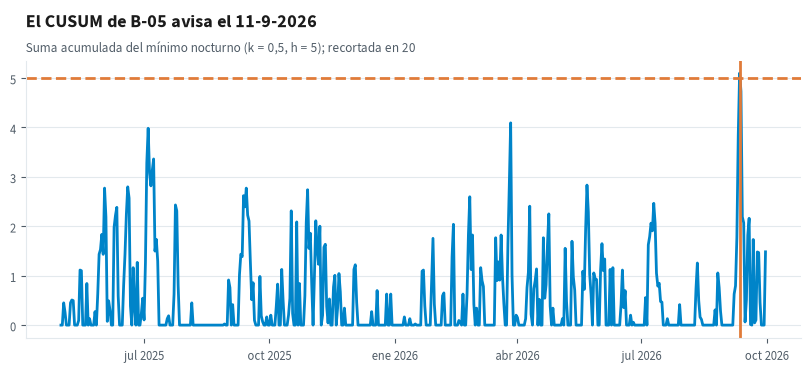

In [18]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(cusum.index, cusum.clip(upper=4 * h), color=estilo.AZUL)
ax.axhline(h, color=estilo.NARANJA, linestyle="--")
if alarma is not None:
    ax.axvline(alarma, color=estilo.NARANJA)
    ax.set_title(f"El CUSUM de {base_candidata} avisa el {fecha(alarma)}")
else:
    ax.set_title(f"El CUSUM de {base_candidata} no avisa")
estilo.subtitulo(ax, f"Suma acumulada del mínimo nocturno (k = {n(k, 1)}, h = {h}); recortada en {4 * h}")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
eje_es(ax)
eje_meses(ax)
plt.show()

Ojo con una cosa: vigilando muchos meses, una base sana también acaba dando alguna falsa alarma
con el CUSUM (en la Jornada 4 lo mediremos). Mirad, además de la fecha, **cuánto sube**: una base
que pierde energía no sube unas décimas, sube kilovatios y se queda arriba.

**Para la puesta en común:** ¿qué base?, ¿desde qué fecha?, ¿con qué margen? Que el margen sea
honesto: decir «el 14 de mayo» con una avería gradual es fingir una precisión que no tenemos.

## Qué os lleváis

- El uso late a tres ritmos a la vez: el día, la semana y el año. Antes de comparar, hay que saber
  cuáles se están mezclando.
- Las series se parecen a sí mismas (0,81 a una semana): no son datos independientes.
- La STL separa lo que se repite de lo que sorprende; el residuo es donde viven las anomalías.
- El mínimo nocturno no tiene estación que lo tape. **Una media mensual esconde exactamente lo
  que se busca.**
- En casa: cambiad `base_stl` y mirad el mínimo nocturno de otras bases en `diario.csv`. Hay más
  averías escondidas.